In [147]:
import pandas as pd
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt


In [86]:
users = pd.read_excel('dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx', sheet_name = 'Пользователи')
payments = pd.read_excel('dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx', sheet_name = 'Платежи')


print("Размер таблицы:", users.shape)
display(users.head())

Размер таблицы: (1504, 5)


,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


In [87]:
users.info()
print("\nПропуски по столбцам:")
print(users.isna().sum())
print("\nКоличество дубликатов строк:", users.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1504 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      1504 non-null   int64 
 1   group        1503 non-null   object
 2   age          1504 non-null   int64 
 3   city         1503 non-null   object
 4   device_type  1504 non-null   object
dtypes: int64(2), object(3)
memory usage: 58.9+ KB

Пропуски по столбцам:
user_id        0
group          1
age            0
city           1
device_type    0
dtype: int64

Количество дубликатов строк: 0


In [88]:
print("Размер таблицы:", payments.shape)
display(payments.head())

Размер таблицы: (2661, 7)


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


In [89]:
payments.info()
print("\nПропуски по столбцам:")
print(payments.isna().sum())
print("\nКоличество дубликатов строк:", payments.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2661 entries, 0 to 2660
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2661 non-null   int64         
 1   user_id          2660 non-null   float64       
 2   group            2661 non-null   object        
 3   step1_opened     2661 non-null   datetime64[ns]
 4   step2_entered    2256 non-null   datetime64[ns]
 5   step3_confirmed  1719 non-null   datetime64[ns]
 6   step4_success    1522 non-null   datetime64[ns]
dtypes: datetime64[ns](4), float64(1), int64(1), object(1)
memory usage: 145.7+ KB

Пропуски по столбцам:
payment_id            0
user_id               1
group                 0
step1_opened          0
step2_entered       405
step3_confirmed     942
step4_success      1139
dtype: int64

Количество дубликатов строк: 0


In [92]:
users_id = users['user_id']
payments['user_id'].isin(users_id).value_counts()

,count
user_id,
True,2660
False,1


In [93]:
merged = payments.merge(
    users,
    on = 'user_id',
    how = 'left'
)

In [94]:
(merged['group_x'] != merged['group_y']).value_counts()

,count
False,2659
True,2


In [95]:
mask = merged['group_x'] != merged['group_y']
merged.loc[mask]

,payment_id,user_id,group_x,step1_opened,step2_entered,step3_confirmed,step4_success,group_y,age,city,device_type
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00,A,26.0,Москва,android
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT,NaN,NaN,NaN,NaN


In [96]:
payments[payments['user_id'] == 1010]

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
14,5015,1010.0,A,2024-04-27 13:26:00,NaT,NaT,NaT
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00


In [97]:
payments[(payments['step3_confirmed'].isna()) & (payments['step4_success'].notna())].shape

(0, 7)

In [98]:
payments[payments['step1_opened'] > payments['step2_entered']].shape

(0, 7)

In [99]:
payments[payments['step2_entered'] > payments['step3_confirmed']].shape

(0, 7)

In [100]:
payments[payments['step3_confirmed'] > payments['step4_success']].shape

(0, 7)

In [101]:
payments[(payments['step2_entered'].isna()) & (payments['step3_confirmed'].notna())].shape

(0, 7)

In [102]:
print(payments['step1_opened'].min())
print(payments['step1_opened'].max())

2024-04-01 00:19:00
2024-04-30 23:17:00


In [103]:
print(payments['step2_entered'].min())
print(payments['step2_entered'].max())

2024-04-01 00:23:00
2024-04-30 23:20:00


In [104]:
print(payments['step3_confirmed'].min())
print(payments['step3_confirmed'].max())

2024-04-01 00:29:00
2024-04-30 23:25:00


In [105]:
print(payments['step4_success'].min())
print(payments['step4_success'].max())

2024-04-01 00:33:00
2024-04-30 23:30:00


In [106]:
users['age'].describe()

,age
count,1504.000000
mean,32.745346
std,8.410915
min,-5.000000
25%,27.000000
50%,33.000000
75%,38.000000
max,150.000000


In [107]:
users['group'].value_counts(dropna = False)

,count
group,
A,752
B,751
NaN,1


In [109]:
users['city'].value_counts(dropna = False)

,count
city,
Москва,595
Регион,514
СПб,394
NaN,1


In [110]:
users['device_type'].value_counts(dropna = False)

,count
device_type,
android,777
ios,727


In [111]:
payments['success'] = payments['step4_success'].notna().astype(int)
payments.head()
payments['success'].value_counts()


,count
success,
1,1522
0,1139


In [112]:
user_success = payments.groupby('user_id')['success'].max().reset_index()
user_success.head()


,user_id,success
0,1001.0,0
1,1002.0,0
2,1003.0,0
3,1004.0,1
4,1005.0,1


In [113]:
full_user_stats = user_success.merge(
    users,
    on = 'user_id',
    how = 'left'
)
conv_a = full_user_stats.groupby('group')['success'].agg({'count', 'sum', 'mean'})['mean'].loc["A"]
conv_b = full_user_stats.groupby('group')['success'].agg({'count', 'sum', 'mean'})['mean'].loc["B"]

print('abs_conv = ', conv_b - conv_a)
print('rel_conv = ', ((conv_b - conv_a) / conv_a) * 100)
abs_conv = conv_b - conv_a
p_a = conv_a
p_b = conv_b
n_a = full_user_stats.groupby('group')['success'].agg({'count', 'sum', 'mean'})['count'].loc["A"]
n_b = full_user_stats.groupby('group')['success'].agg({'count', 'sum', 'mean'})['count'].loc["B"]
x_a = full_user_stats.groupby('group')['success'].agg({'count', 'sum', 'mean'})['sum'].loc["A"]
x_b = full_user_stats.groupby('group')['success'].agg({'count', 'sum', 'mean'})['sum'].loc["B"]

p_pool = (x_a + x_b) / (n_a + n_b)
SE = np.sqrt(p_pool * (1 - p_pool) * (1 / (n_a) + 1 / (n_b)))
Z = (conv_b - conv_a) / SE
print(p_pool, SE, Z)



abs_conv =  0.1462103861517976
rel_conv =  22.227530364372466
0.7308461025982678 0.02289565382247542 6.385945004473767


In [116]:
p_value = norm.sf(Z)
print(p_value)

8.517110800409756e-11


In [117]:
SE_CI = np.sqrt((p_a * (1 - p_a) / n_a) + (p_b * (1 - p_b) / n_b))
CI_high = abs_conv + 1.96 * SE_CI
CI_low = abs_conv - 1.96 * SE_CI

print(SE_CI, CI_high, CI_low)

0.022579834685760327 0.19046686213588784 0.10195391016770736


In [118]:

clean_stats = full_user_stats[
    full_user_stats['user_id'] != 1010
].copy()


clean_result = clean_stats.groupby('group')['success'].agg(['count', 'sum', 'mean'])

print(clean_result)


clean_diff = clean_result.loc['B', 'mean'] - clean_result.loc['A', 'mean']

print(f'Прирост конверсии: {clean_diff * 100:.2f} п.п.')



       count  sum      mean
group                      
A        750  493  0.657333
B        750  603  0.804000
Прирост конверсии: 14.67 п.п.


In [119]:

payments['entered'] = payments['step2_entered'].notna().astype(int)


user_entered = payments.groupby('user_id')['entered'].max().reset_index()

user_entered_stats = user_entered.merge(
    users,
    on = 'user_id',
    how = 'left'
)
user_entered_stats.groupby('group')['entered'].agg({'count', 'sum', 'mean'})

,mean,count,sum
group,,,
A,0.894807,751,672
B,0.942667,750,707


In [120]:
payments['confirmed'] = payments['step3_confirmed'].notna().astype(int)

user_confirmed = (
    payments.groupby('user_id')['confirmed']
    .max()
    .reset_index()
)

user_confirmed = user_confirmed.merge(
    users[['user_id', 'group']],
    on='user_id',
    how='left'
)

confirmed = user_confirmed.groupby('group')['confirmed'].sum()
entered = user_entered_stats.groupby('group')['entered'].sum()

transition_23 = (confirmed / entered * 100).round(2)

print(transition_23)

group
A    81.70
B    91.09
dtype: float64


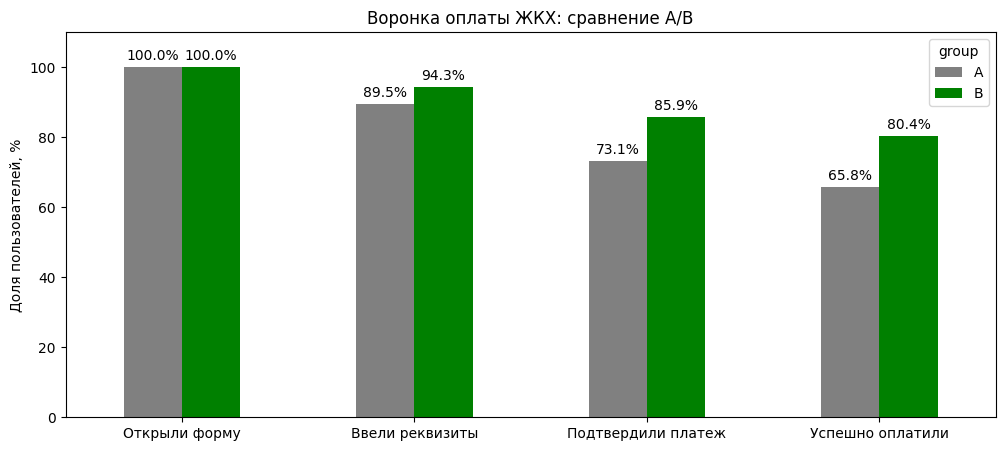

In [192]:
payments1 = payments.copy()
payments1['opened'] = payments1['step1_opened'].notna().astype(int)
payments1['entered'] = payments1['step2_entered'].notna().astype(int)
payments1['confirmed'] = payments1['step3_confirmed'].notna().astype(int)
payments1['success'] = payments1['step4_success'].notna().astype(int)



payments2 = payments1[['user_id', 'opened', 'entered', 'confirmed', 'success']].groupby('user_id').max().reset_index()


funnel_users = payments2.merge(
    users[['user_id', 'group']],
    on = 'user_id',
    how = 'left'
)
funnel_counts = funnel_users.groupby('group')[['opened', 'entered', 'confirmed', 'success']].sum()
funnel_plt = funnel_counts.div(funnel_counts['opened'], axis = 0) * 100
ax = funnel_plt.T.plot(kind = 'bar', figsize = (12, 5), color = ['grey', 'green'], rot = 0, ylim = (0, 110), fontsize = 10)
ax.set_title('Воронка оплаты ЖКХ: сравнение A/B')
ax.set_ylabel('Доля пользователей, %')
ax.set_xticklabels(['Открыли форму', 'Ввели реквизиты', 'Подтвердили платеж', 'Успешно оплатили'])
for i in ax.containers:
  ax.bar_label(i, fmt = '%.1f%%', padding = 3)



In [195]:
full_user_stats.groupby(['device_type', 'group'])['success'].agg(['count', 'sum', 'mean'])


count  sum      mean
device_type group                      
android     A        407  263  0.646192
            B        369  295  0.799458
ios         A        344  231  0.671512
            B        381  308  0.808399

In [196]:
full_user_stats.groupby(['city', 'group'])['success'].agg(['count', 'sum', 'mean'])

count  sum      mean
city   group                      
Москва A        288  181  0.628472
       B        306  248  0.810458
Регион A        268  179  0.667910
       B        245  187  0.763265
СПб    A        194  133  0.685567
       B        199  168  0.844221

In [197]:
age_users = full_user_stats.copy()
age_users = age_users[(age_users['age'] >= 18) & (age_users['age'] <= 100)]
age_users['age_group'] = pd.cut(age_users['age'], [19, 29, 39, 100], labels=['20-29', '30-39', '40-60'])
age_stats = age_users.groupby(['age_group', 'group'], observed=True)['success'].agg(['count', 'sum', 'mean'])
age_stats


count  sum      mean
age_group group                      
20-29     A        269  185  0.687732
          B        267  220  0.823970
30-39     A        334  215  0.643713
          B        325  254  0.781538
40-60     A        148   94  0.635135
          B        158  129  0.816456

In [198]:
age_conv = age_stats['mean'].unstack()
age_conv['diff'] = (age_conv['B'] - age_conv['A']) * 100
age_conv


group,A,B,diff
age_group,,,
20-29,0.687732,0.823970,13.623770
30-39,0.643713,0.781538,13.782589
40-60,0.635135,0.816456,18.132056


In [199]:
from scipy.stats import chi2
d = []
w = []
for i in age_conv.index:
    a = age_stats.loc[(i, 'A')]
    b = age_stats.loc[(i, 'B')]
    d.append(b['mean'] - a['mean'])
    w.append(1 / (a['mean'] * (1-a['mean']) / a['count'] + b['mean'] * (1-b['mean']) / b['count']))

m = sum(d[i] * w[i] for i in range(3)) / sum(w)
Q = sum(w[i] * (d[i] - m)**2 for i in range(3))
p_age = chi2.sf(Q, 2)
print(Q, p_age)


0.6223528945851557 0.7325846018950578
